> **Archived notebook.** This is a predecessor of [`BruSafe_05_M5_absolute_quantification.ipynb`](../BruSafe_05_M5_absolute_quantification.ipynb), kept for provenance under the module numbering used before the framework document fixed modules M1–M5. It is not part of the current pipeline and should not be run: it contains results that were later corrected (the 300 min lactose horizon, the uncensored Beta likelihood in the partition module, OD and band volume as primary observables, and a contact energy of −4.2 kcal mol⁻¹ without a source). The original text and outputs below are unchanged.

# BruSafe · Module M6 — The Keystone Number: cargo copies per particle, and what it buys

**iGEM Tec-Chihuahua 2026 · CAPSID framework**

Everything upstream produces *ratios* or *closed shells*. This notebook produces the one measurement
that converts them into absolute, dose-relevant quantities:

$$\mathrm{CPP} \;=\; \frac{\text{dPCR copies of RNase-protected cargo, per mL}}{\text{particle count, per mL}}$$

## Why this one number

| Without CPP | With CPP |
|---|---|
| M3.5 gives $P(3\times)/P(0\times)$ — a ratio with no absolute scale | absolute packaging fraction |
| M3 gives closed shells, empty or full | **loaded** VLP concentration |
| yield in mg/L of coat protein | **doses per litre of culture** |

It is also the only place the dPCR panel and the assembly module measure the same physical object,
which is what makes it a cross-check rather than two unrelated assays.

## What this notebook is for

1. **Design the measurement** so it is not dominated by an avoidable error (§2–§4).
2. **Propagate it** into loaded-VLP concentration and doses per litre (§5).
3. **Find the scale-up bottleneck** — which of the six factors in the chain actually moves cost per
   dose, so effort goes where it matters (§6).

> **⚠ Read §2.2 before booking instrument time.** The obvious choice for the denominator — NTA — is
> marginal at 27 nm, and the cheapest route turns out to be more precise than particle counting.
> That conclusion is quantified, not asserted.

---
## 1 · Setup

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

RNG = np.random.default_rng(20261013)
N_DRAW = 60000
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})

# --- particle constants -----------------------------------------------------
M_CP        = 13.7e3        # g/mol, MS2 coat protein monomer
N_MONO_VLP  = 180.0         # monomers per T=3 shell
M_PROT_VLP  = M_CP*N_MONO_VLP          # 2.47 MDa of protein per shell
CARGO_NT    = 1227.0        # cargo mRNA length, nt  <-- EDIT to your construct
M_NT        = 330.0         # g/mol per nucleotide (Na+ form)
M_CARGO     = CARGO_NT*M_NT
NA          = 6.02214076e23

print(f"VLP protein mass : {M_PROT_VLP/1e6:.2f} MDa")
print(f"cargo mass       : {M_CARGO/1e3:.0f} kDa ({CARGO_NT:.0f} nt)")
print(f"loaded particle  : {(M_PROT_VLP+M_CARGO)/1e6:.2f} MDa "
      f"({100*M_CARGO/(M_PROT_VLP+M_CARGO):.0f}% RNA by mass at 1 copy/particle)")

VLP protein mass : 2.47 MDa
cargo mass       : 405 kDa (1227 nt)
loaded particle  : 2.87 MDa (14% RNA by mass at 1 copy/particle)


---
## 2 · The two measurements

### 2.1 · Numerator — dPCR of RNase-protected cargo

$$C_{meas} = C_{true}\,\varepsilon_{rel}\,\varepsilon_{ext} \;+\; B$$

Three things can go wrong, and each needs its own control:

| Factor | What it does | Control |
|---|---|---|
| $\varepsilon_{rel}$ — capsid disruption | incomplete release undercounts | spike a known RNA into intact VLPs, disrupt, recover |
| $\varepsilon_{ext}$ — extraction recovery | undercounts | external RNA spike through the full protocol |
| $B$ — protection carryover | surviving free RNA **over**counts | naked cargo RNA + RNase, no capsid |

The carryover control is the one teams skip and the one that matters most: it is the only term that
biases the answer *upward*, and an uncorrected upward bias on the numerator inflates every downstream
dose estimate.

**dPCR counting precision is not your problem.** At 26k partitions the counting CV is under 1% across
the whole usable occupancy range. Your uncertainty is prep, not partitions — §3 shows this
quantitatively. Quoting the partition CV as your error bar understates it by more than an order of
magnitude.

**EvaGreen constraint.** No probe multiplexing, so cargo and reference cannot share a well by colour.
Either resolve by amplicon length (amplitude discrimination) or run separate wells and carry the
between-well variance explicitly. Do not treat separate-well ratios as duplexed.

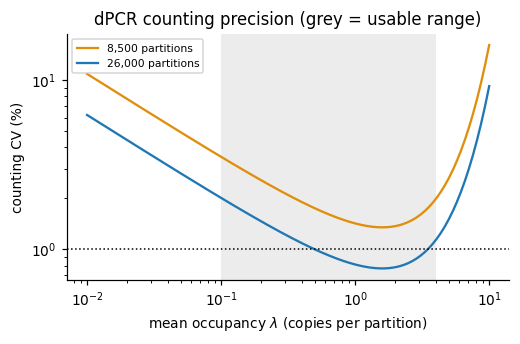

optimal occupancy      : lambda = 1.59  -> CV = 0.77%
CV across lambda 0.1-4 : 2.01% to 1.14%
Dilute to land in the grey band, then stop worrying about the dPCR step.


In [ ]:
def dpcr_cv(lam, n_part=26000):
    # CV of the estimated concentration from Poisson partitioning
    return np.sqrt((np.exp(lam) - 1.0)/(n_part*lam**2))

lam = np.logspace(-2, 1.0, 200)
plt.figure(figsize=(4.8, 3.2))
for n, c in zip((8500, 26000), ["#e08e0b", "#1f77b4"]):
    plt.loglog(lam, 100*dpcr_cv(lam, n), color=c, label=f"{n:,} partitions")
plt.axvspan(0.1, 4.0, color="grey", alpha=.15, lw=0)
plt.axhline(1.0, color="k", ls=":", lw=1)
plt.xlabel(r"mean occupancy $\lambda$ (copies per partition)")
plt.ylabel("counting CV (%)"); plt.legend(fontsize=7)
plt.title("dPCR counting precision (grey = usable range)")
plt.tight_layout(); plt.show()

lam_opt = lam[np.argmin(dpcr_cv(lam))]
print(f"optimal occupancy      : lambda = {lam_opt:.2f}  -> CV = {100*dpcr_cv(lam_opt):.2f}%")
print(f"CV across lambda 0.1-4 : {100*dpcr_cv(0.1):.2f}% to {100*dpcr_cv(4.0):.2f}%")
print("Dilute to land in the grey band, then stop worrying about the dPCR step.")

### 2.2 · Denominator — counting particles, honestly

| Method | Works at 27 nm? | Precision | Note |
|---|---|---|---|
| **NTA** | **marginal** | poor | practical floor ~30–50 nm for low-index biologicals; MS2 VLPs sit at or below it |
| TRPS | marginal | moderate | smallest pores ~40 nm |
| Negative-stain TEM | yes | counting-limited | adsorption and field-selection bias need a bead standard |
| SEC-MALS | yes | excellent | absolute molar mass; also separates loaded from empty by mass |
| **SEC peak + protein assay** | yes | **good** | cheapest; precision derived below |

The last row is the surprise: converting the purified capsid peak's **protein mass** to particles via
$M_{prot,VLP}$ is more precise than counting particles, because counting error goes as
$1/\sqrt{n}$ and you rarely count more than a few hundred.

$$N_{particles} = \frac{m_{protein}\,N_A}{M_{prot,VLP}}$$

> **⚠ Do not use A280 alone on a loaded VLP.** RNA absorbs strongly at 280 nm, so A280 overstates
> protein. The two-wavelength deconvolution looks like the fix, but §2.3 shows it is
> ill-conditioned in exactly this regime. Use an RNA-insensitive protein assay (BCA, Bradford)
> for the numerator of the equation above, and A260 for RNA.

In [ ]:
def particles_from_protein(mass_prot_mg_per_mL):
    # mg/mL of capsid-peak protein -> particles per mL
    return mass_prot_mg_per_mL*1e-3*NA/M_PROT_VLP

def tem_cv(n_counted, overdispersion=1.8):
    # field-to-field clustering inflates the Poisson CV; 1.8 is a typical factor
    return overdispersion/np.sqrt(n_counted)

print(f"{'method':<28} {'CV':>8}   basis")
print(f"{'TEM, 200 particles':<28} {100*tem_cv(200):7.1f}%   counting + field clustering")
print(f"{'TEM, 1000 particles':<28} {100*tem_cv(1000):7.1f}%   counting + field clustering")
print(f"{'SEC peak + BCA':<28} {100*np.sqrt(.05**2+.05**2+.03**2):7.1f}%   assay 5%, integration 5%, dilution 3%")
print("\nCounting 1000 particles by TEM - a real afternoon of work - is still less")
print("precise than a protein assay on the same material. Use TEM as the")
print("ORTHOGONAL check on shape and malformed fraction, which no protein assay")
print("can give you, and let the protein assay carry the number.")

method                             CV   basis
TEM, 200 particles              12.7%   counting + field clustering
TEM, 1000 particles              5.7%   counting + field clustering
SEC peak + BCA                   7.7%   assay 5%, integration 5%, dilution 3%

Counting 1000 particles by TEM - a real afternoon of work - is still less
precise than a protein assay on the same material. Use TEM as the
ORTHOGONAL check on shape and malformed fraction, which no protein assay
can give you, and let the protein assay carry the number.


### 2.3 · Why the A260/A280 deconvolution fails here

Two components, two wavelengths:

$$\begin{pmatrix}A_{260}\\A_{280}\end{pmatrix} =
\begin{pmatrix}\varepsilon^{260}_{prot} & \varepsilon^{260}_{RNA}\\
\varepsilon^{280}_{prot} & \varepsilon^{280}_{RNA}\end{pmatrix}
\begin{pmatrix}c_{prot}\\c_{RNA}\end{pmatrix}$$

RNA absorbs ~25× more per unit mass than protein at 260 nm, so in a loaded VLP the protein estimate
is a small difference between two large numbers. The condition number below says how badly a 1%
absorbance error is amplified into the protein mass.

In [ ]:
# mass extinction coefficients, (mg/mL)^-1 cm^-1
E = np.array([[0.57, 25.0],      # A260: protein, RNA
              [1.00, 12.5]])     # A280: protein, RNA
cond = np.linalg.cond(E)
print(f"condition number of the 2x2 system : {cond:.1f}")
print(f"-> a 1% absorbance error becomes up to {cond:.0f}% error in the protein mass\n")

for copies in (0, 1, 2, 4):
    m_rna = copies*M_CARGO/M_PROT_VLP          # RNA:protein mass ratio
    c = np.array([1.0, m_rna])
    A = E @ c
    print(f"  {copies} copies/particle: A260/A280 = {A[0]/A[1]:.3f}, "
          f"RNA is {100*E[0,1]*c[1]/A[0]:4.1f}% of A260 and {100*E[1,1]*c[1]/A[1]:4.1f}% of A280")
print("\nA260/A280 IS a good readout for RNA per particle - RNA dominates both")
print("channels. It is a bad readout for protein. Split the job: A260 for RNA,")
print("BCA for protein. And note A260 counts ALL packaged RNA including host,")
print("so comparing it against the dPCR cargo count gives you the packaged-RNA")
print("specificity for free - see S5.")

condition number of the 2x2 system : 43.8
-> a 1% absorbance error becomes up to 44% error in the protein mass

  0 copies/particle: A260/A280 = 0.570, RNA is  0.0% of A260 and  0.0% of A280
  1 copies/particle: A260/A280 = 1.532, RNA is 87.8% of A260 and 67.2% of A280
  2 copies/particle: A260/A280 = 1.720, RNA is 93.5% of A260 and 80.4% of A280
  4 copies/particle: A260/A280 = 1.845, RNA is 96.6% of A260 and 89.1% of A280

A260/A280 IS a good readout for RNA per particle - RNA dominates both
channels. It is a bad readout for protein. Split the job: A260 for RNA,
BCA for protein. And note A260 counts ALL packaged RNA including host,
so comparing it against the dPCR cargo count gives you the packaged-RNA
specificity for free - see S5.


---
## 3 · The estimator and where its error comes from

$$\widehat{\mathrm{CPP}} = \frac{(C_{meas}-B)/(\varepsilon_{rel}\varepsilon_{ext})}{N_{particles}}$$

Monte Carlo below. **Edit the four `MEASURED_` blocks with your own control results** — the values
here are plausible placeholders, not data.

In [ ]:
# ---- SWAP POINT: replace each with your measured control -------------------
MEASURED_release   = (0.90, 0.06)     # mean, sd  (spike into intact VLP, disrupt, recover)
MEASURED_extract   = (0.72, 0.08)     # mean, sd  (external RNA spike, full protocol)
MEASURED_carry_pct = (0.03, 0.015)    # fraction of the signal that is unprotected carryover
MEASURED_prot_CV   = 0.077            # SEC peak + BCA, from S2.2

C_meas_per_mL = 2.5e13                # dPCR, protected cargo copies per mL
PROT_mg_per_mL = 0.25                 # capsid-peak protein

eps_rel  = np.clip(RNG.normal(*MEASURED_release, N_DRAW), 0.05, 1.0)
eps_ext  = np.clip(RNG.normal(*MEASURED_extract, N_DRAW), 0.05, 1.0)
carry    = np.clip(RNG.normal(*MEASURED_carry_pct, N_DRAW), 0.0, 0.9)
lam_used = 1.5
C_meas   = C_meas_per_mL*(1 + RNG.normal(0, dpcr_cv(lam_used), N_DRAW))
prot     = PROT_mg_per_mL*(1 + RNG.normal(0, MEASURED_prot_CV, N_DRAW))

C_true = C_meas*(1.0 - carry)/(eps_rel*eps_ext)
N_part = particles_from_protein(prot)
CPP    = C_true/N_part

def q(x): return np.percentile(x, [2.5, 50, 97.5])
lo, mdn, hi = q(CPP)
print(f"particles per mL        : {np.median(N_part):.3g}")
print(f"CARGO COPIES PER PARTICLE: {mdn:.3f}   95% [{lo:.3f}, {hi:.3f}]   "
      f"span {hi/lo:.2f}x")

logs = {"capsid disruption": np.log(eps_rel), "extraction recovery": np.log(eps_ext),
        "protection carryover": np.log(1-carry), "dPCR counting": np.log(C_meas/C_meas_per_mL),
        "particle count (protein)": np.log(prot/PROT_mg_per_mL)}
tot = np.var(np.log(CPP))
print("\nERROR BUDGET (share of log-variance)")
for k, v in sorted(logs.items(), key=lambda kv: -np.var(kv[1])):
    print(f"  {k:<26s} {100*np.var(v)/tot:5.1f} %")
print("\ndPCR counting is negligible. The recovery controls dominate, which is")
print("why S2.1 insists on running them rather than assuming efficiency = 1.")

particles per mL        : 6.1e+13
CARGO COPIES PER PARTICLE: 0.618   95% [0.467, 0.849]   span 1.82x

ERROR BUDGET (share of log-variance)
  extraction recovery         55.0 %
  particle count (protein)    25.7 %
  capsid disruption           18.0 %
  protection carryover         1.0 %
  dPCR counting                0.3 %

dPCR counting is negligible. The recovery controls dominate, which is
why S2.1 insists on running them rather than assuming efficiency = 1.


---
## 4 · Design — what precision costs

How good does CPP need to be? It multiplies straight through to doses per litre, so its CV adds in
quadrature to everything else in §6. The scan below shows what tightening each control buys.

In [ ]:
def cpp_cv(rel_sd=0.06, ext_sd=0.08, carry_sd=0.015, prot_cv=0.077,
           n_tech=1, n_bio=3, n=40000, rng=RNG):
    # technical replicates average the dPCR + protein steps; biological
    # replicates average everything, including the recovery controls
    r  = np.clip(rng.normal(0.90, rel_sd/np.sqrt(n_bio), n), .05, 1)
    e  = np.clip(rng.normal(0.72, ext_sd/np.sqrt(n_bio), n), .05, 1)
    cy = np.clip(rng.normal(0.03, carry_sd/np.sqrt(n_bio), n), 0, .9)
    c  = 1 + rng.normal(0, dpcr_cv(1.5)/np.sqrt(n_tech*n_bio), n)
    p  = 1 + rng.normal(0, prot_cv/np.sqrt(n_tech*n_bio), n)
    x  = c*(1-cy)/(r*e*p)
    return float(np.std(np.log(x)))

rows = [dict(scenario="no controls (assume eps = 1)", cv=cpp_cv(rel_sd=.20, ext_sd=.25, carry_sd=.10)),
        dict(scenario="controls, 3 bio reps",         cv=cpp_cv()),
        dict(scenario="controls, 6 bio reps",         cv=cpp_cv(n_bio=6)),
        dict(scenario="controls + duplicate wells",   cv=cpp_cv(n_bio=6, n_tech=2))]
d = pd.DataFrame(rows); d["CV_%"] = 100*d.cv; d["95%_span"] = np.exp(2*1.96*d.cv)
display(d[["scenario", "CV_%", "95%_span"]].round(2))
print("Running the recovery controls at all is worth more than any amount of")
print("replication without them. Beyond ~6 biological replicates the return")
print("flattens - spend the next unit of effort on S6's bottleneck instead.")

,scenario,CV_%,95%_span
0,no controls (assume eps = 1),24.73,2.64
1,"controls, 3 bio reps",8.80,1.41
2,"controls, 6 bio reps",6.23,1.28
3,controls + duplicate wells,5.77,1.25


Running the recovery controls at all is worth more than any amount of
replication without them. Beyond ~6 biological replicates the return
flattens - spend the next unit of effort on S6's bottleneck instead.


---
## 5 · From CPP to loaded VLPs, and the specificity bonus

Two quantities fall out immediately:

$$f_{loaded} = \min(\mathrm{CPP},\,1)\ \text{(if } \le 1 \text{ copy fits)}, \qquad
\text{specificity} = \frac{\mathrm{CPP}\times M_{cargo}}{\text{total RNA per particle from } A_{260}}$$

The second is free: A260 counts **all** packaged RNA, dPCR counts only cargo, and the ratio is the
fraction of packaged RNA that is the construct. That is the absolute packaging fraction M3.5 could
only give as a ratio.

In [ ]:
A260_per_particle_ng = 0.0            # set from your A260 on the capsid peak; 0 = skip
TOTAL_RNA_nt_per_particle = 1600.0    # <-- from A260/BCA on the SEC peak; placeholder

f_loaded = np.clip(CPP, 0, 1)
specificity = np.clip(CPP*CARGO_NT/TOTAL_RNA_nt_per_particle, 0, 1)
lo, mdn, hi = q(f_loaded); print(f"loaded fraction        : {mdn:.3f}  95% [{lo:.3f}, {hi:.3f}]")
lo, mdn, hi = q(specificity); print(f"packaging specificity  : {mdn:.3f}  95% [{lo:.3f}, {hi:.3f}]")
print("\nSpecificity is the number M3.5's dPCR ladder cannot produce on its own -")
print("it needs the particle count. Cross-check it against the P(3x)/P(0x)")
print("enrichment: the two must be consistent, and if they are not, one of the")
print("two assays has a systematic error you have not found yet.")

loaded fraction        : 0.618  95% [0.467, 0.849]
packaging specificity  : 0.474  95% [0.358, 0.651]

Specificity is the number M3.5's dPCR ladder cannot produce on its own -
it needs the particle count. Cross-check it against the P(3x)/P(0x)
enrichment: the two must be consistent, and if they are not, one of the
two assays has a systematic error you have not found yet.


---
## 6 · Scalability

Chain from culture volume to doses:

$$\text{doses/L} = \frac{[\mathrm{CP}]_{mg/L}\times f_{sol}\times f_{cap}\times f_{loaded}\times \eta_{purif}}{d_{mg}}$$

**Every input below is a placeholder.** Dose size in particular must come from your immunology and
human-practices work, not from this notebook. What the analysis is *for* is the tornado in §6.2 —
which factor moves cost per dose — and that ranking is far more robust than any absolute figure.

In [ ]:
# ---- SWAP POINT: process and product assumptions ---------------------------
CP_mg_per_L   = (178.0, 18.0)      # total CP at harvest, mean/sd (from M0-M4)
F_SOL         = (0.438, 0.020)     # M2.5
F_CAP         = (0.86, 0.05)       # M3, ASSUMES contacts counted from 2MS2
ETA_PURIF     = (0.45, 0.12)       # clarification + PEG + SEC, overall recovery
DOSE_MG       = (0.10, 0.03)       # mg VLP protein per dose  <-- immunology input
COST_PER_L    = 4.0                # USD per L of culture, media + induction + labour

def draw(ms, n=N_DRAW, lo=1e-6, hi=None):
    x = RNG.normal(ms[0], ms[1], n)
    return np.clip(x, lo, hi if hi is not None else np.inf)

cp   = draw(CP_mg_per_L)
fs   = np.clip(draw(F_SOL), 0, 1)
fc   = np.clip(draw(F_CAP), 0, 1)
fl   = np.clip(RNG.choice(f_loaded, N_DRAW), 0, 1)
eta  = np.clip(draw(ETA_PURIF), 0, 1)
dose = draw(DOSE_MG)

mg_loaded_per_L = cp*fs*fc*fl*eta
doses_per_L     = mg_loaded_per_L/dose
L_per_1000      = 1000.0/np.maximum(doses_per_L, 1e-9)
cost_per_dose   = COST_PER_L/np.maximum(doses_per_L, 1e-9)

for lab, x, u in [("loaded VLP protein", mg_loaded_per_L, "mg/L culture"),
                  ("doses per litre",    doses_per_L,     "doses/L"),
                  ("culture per 1000 doses", L_per_1000,  "L"),
                  ("culture cost per dose",  cost_per_dose, "USD (media+induction only)")]:
    lo_, md_, hi_ = q(x)
    print(f"  {lab:<24s} {md_:10.4g}   95% [{lo_:.3g}, {hi_:.3g}]  {u}")
print("\nCulture cost only. Purification consumables, QC, fill-finish and")
print("regulatory burden are not here and will dominate a real cost of goods.")

  loaded VLP protein            18.36   95% [8.15, 33.1]  mg/L culture
  doses per litre               186.3   95% [71.9, 526]  doses/L
  culture per 1000 doses        5.367   95% [1.9, 13.9]  L
  culture cost per dose       0.02147   95% [0.0076, 0.0556]  USD (media+induction only)

Culture cost only. Purification consumables, QC, fill-finish and
regulatory burden are not here and will dominate a real cost of goods.


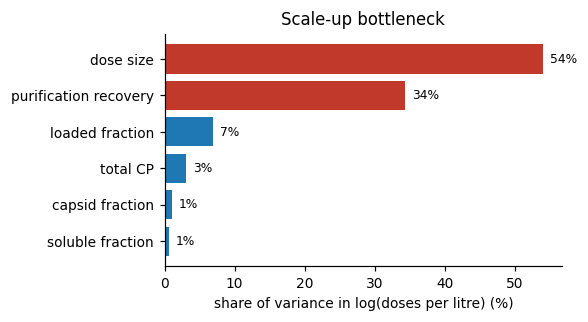

Read this as a work-allocation plan, not a result. The two red bars are
where an extra week of effort changes the answer; the blue ones are
already good enough that improving them changes nothing you can measure.


In [ ]:
# --- 6.2 tornado: which factor actually moves doses per litre? --------------
base = {"total CP": cp, "soluble fraction": fs, "capsid fraction": fc,
        "loaded fraction": fl, "purification recovery": eta, "dose size": dose}
tot = np.var(np.log(doses_per_L))
share = {}
for k, v in base.items():
    s = np.var(np.log(np.maximum(v, 1e-12)))/tot
    share[k] = 100*s
ser = pd.Series(share).sort_values()

fig, ax = plt.subplots(figsize=(5.4, 3.0))
ax.barh(ser.index, ser.values, color=["#c0392b" if v > 20 else "#1f77b4" for v in ser.values])
ax.set_xlabel("share of variance in log(doses per litre) (%)")
ax.set_title("Scale-up bottleneck")
for i, v in enumerate(ser.values): ax.text(v+1, i, f"{v:.0f}%", va="center", fontsize=8)
fig.tight_layout(); plt.show()

print("Read this as a work-allocation plan, not a result. The two red bars are")
print("where an extra week of effort changes the answer; the blue ones are")
print("already good enough that improving them changes nothing you can measure.")

---
## 7 · What next

**The measurement, in order.**

1. Purify to a clean SEC capsid peak — everything here assumes the peak is not contaminated with
   free dimer or partial shells. Check the trace before running anything else.
2. Run the **three recovery controls** (§2.1). Skipping them costs more precision than any amount of
   replication buys back (§4).
3. Split the readout: **BCA for protein, A260 for RNA, dPCR for cargo.** Do not use A280 on a loaded
   particle (§2.3), and do not use NTA as your particle counter at 27 nm (§2.2).
4. Three biological replicates minimum; six if the schedule allows.
5. TEM as the orthogonal check — on *shape and malformed fraction*, which no bulk assay gives you,
   not as the particle counter.

**Cross-checks that must agree, and what it means if they don't.**

- Specificity from §5 vs the $P(3\times)/P(0\times)$ enrichment from M3.5. Inconsistent → one assay has
  a systematic error.
- Particles from protein mass vs particles from TEM counting. A ratio far from 1 is adsorption bias
  in the TEM, or non-capsid protein in the SEC peak.
- CPP well above 1 copy per particle → either the cargo is fragmenting and being counted more than
  once, or the protection step is leaking. Both are numerator problems.

**Honest scope.** Every number in §5 and §6 is a placeholder. The notebook's output that does *not*
depend on the placeholders is the error budget in §3 and the ranking in §6.2 — those are structural
and can be quoted now. The absolute figures cannot.

### References

1. Huggett JF, Foy CA, Benes V, et al. The digital MIQE guidelines: minimum information for publication of quantitative digital PCR experiments. *Clin Chem.* 2013;59(6):892–902.
2. Whale AS, Huggett JF, Tzonev S. Fundamentals of multiplexing with digital PCR. *Biomol Detect Quantif.* 2016;10:15–23.
3. Pinheiro LB, Coleman VA, Hindson CM, et al. Evaluation of a droplet digital PCR format for DNA copy number quantification. *Anal Chem.* 2012;84(2):1003–1011.
4. Filipe V, Hawe A, Jiskoot W. Critical evaluation of nanoparticle tracking analysis by NanoSight for the measurement of nanoparticles and protein aggregates. *Pharm Res.* 2010;27(5):796–810.
5. Vogt S, Stadlmayr G, Grillari J, Rüker F, Wozniak-Knopp G. Comparison of nanoparticle tracking and multi-angle DLS for VLP characterisation. *Methods Mol Biol.* 2016.
6. Some D, Amartely H, Tsadok A, Lebendiker M. Characterization of proteins by SEC-MALS. *J Vis Exp.* 2019;(148):e59615.
7. Porterfield JZ, Zlotnick A. A simple and general method for determining the protein and nucleic acid content of viruses by UV absorbance. *Virology.* 2010;407(2):281–288.
8. Pickett GG, Peabody DS. Encapsidation of heterologous RNAs by bacteriophage MS2 coat protein. *Nucleic Acids Res.* 1993;21(19):4621–4626.
9. Legendre D, Fastrez J. Production in *Saccharomyces cerevisiae* of MS2 virus-like particles packaging functional heterologous mRNAs. *J Biotechnol.* 2005;117(2):183–194.
10. Zeltins A. Construction and characterization of virus-like particles: a review. *Mol Biotechnol.* 2013;53(1):92–107.